# 量子計算の利点と制約

この章では、量子コンピューターで何が速くなり、何が制約になるかを、探索問題を例に確かめます。量子回路の作り方と、重ね合わせ・干渉・測定の基本は、第2章「量子コンピューターの基礎」で扱いました。

## 量子コンピューターによる高速化:探索問題を例に

量子コンピューターが、古典コンピューターよりどれだけ少ない手順で解けるかを、探索問題で確かめます。

### 例題: 当たりの箱を探す

$N$ 個の箱が並んでいて、そのうち1つだけが当たりです。どれが当たりかは、箱を開けて中を確かめるまで分かりません。箱の並びにヒントもありません。

![N個の箱が並び、そのうち1つだけが当たり。中身は開けてみるまで分からない](./resources/ch03-unstructured-search.svg)

ヒントがないので、古典のコンピューターは箱を1つずつ開けていくしかありません。運が良ければ1回目で当たり、運が悪ければ最後の1個まで開けることになります。箱をランダムな順に開ける試行を1万回繰り返して、当たりが見つかるまでに開けた回数の平均を求めます。

In [1]:
import random


def count_boxes_opened(n_boxes, rng):
    """当たりの箱をランダムな順に1つずつ開けて、見つかるまでに開けた回数を返す。"""
    winner = rng.randrange(n_boxes)
    order = rng.sample(range(n_boxes), n_boxes)
    return order.index(winner) + 1


rng = random.Random(12345)
TRIALS = 10000

for n_boxes in (4, 8, 16):
    average = sum(count_boxes_opened(n_boxes, rng) for _ in range(TRIALS)) / TRIALS
    print(f"箱が{n_boxes:>2}個: 平均 {average:.2f} 回で当たりが見つかった")

箱が 4個: 平均 2.50 回で当たりが見つかった
箱が 8個: 平均 4.50 回で当たりが見つかった
箱が16個: 平均 8.47 回で当たりが見つかった


箱の数が2倍になると、開ける回数もほぼ2倍になります。箱が $N$ 個のとき、平均は $(N+1)/2$ 回です。

### 量子コンピューターの場合

同じ探索を、量子コンピューターのシミュレーターで実行します。使うのは **Grover のアルゴリズム** という、探索のための手法です。Grover の回路は、次の2つの部分の組を、決まった回数だけ繰り返す形をしています。

- **オラクル:** 「この箱は当たりか」を判定する部分。
- **拡散操作:** 当たりの箱が測定で得られる確率を高める部分。

この教材では、2つの部分の中身には立ち入りません。Qiskit が用意している関数 `grover_operator` で、組を作ります。次のセルは、この章で使う回路を作る関数をまとめたものです。当たりは、すべてのビットが1の箱($|11\cdots1\rangle$)に決めておきます。

In [2]:
import math

from qiskit import QuantumCircuit
from qiskit.circuit.library import grover_operator
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector


def make_oracle(n):
    """n量子ビットのオラクル。当たりの箱 |11...1> を判定する。"""
    qc = QuantumCircuit(n, name="oracle")
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)
    return qc


def make_grover(n, iterations, measure=True):
    """n量子ビット(箱は 2**n 個)の Grover の回路。オラクルと拡散操作の組を iterations 回繰り返す。"""
    step = grover_operator(make_oracle(n))  # オラクルと拡散操作の組(Qiskit が用意したもの)
    qc = QuantumCircuit(n)
    qc.h(range(n))  # すべての箱の重ね合わせから始める
    for _ in range(iterations):
        qc.compose(step, inplace=True)
    if measure:
        qc.measure_all()
    return qc


def optimal_iterations(n):
    """当たりの確率が最大になる繰り返しの回数(箱は 2**n 個)。"""
    return round(math.pi / 4 * math.sqrt(2**n) - 0.5)


def success_probability(n, iterations):
    """当たりが得られる確率の理論値(状態ベクトルから計算する)。"""
    return Statevector(make_grover(n, iterations, measure=False)).probabilities_dict().get("1" * n, 0.0)

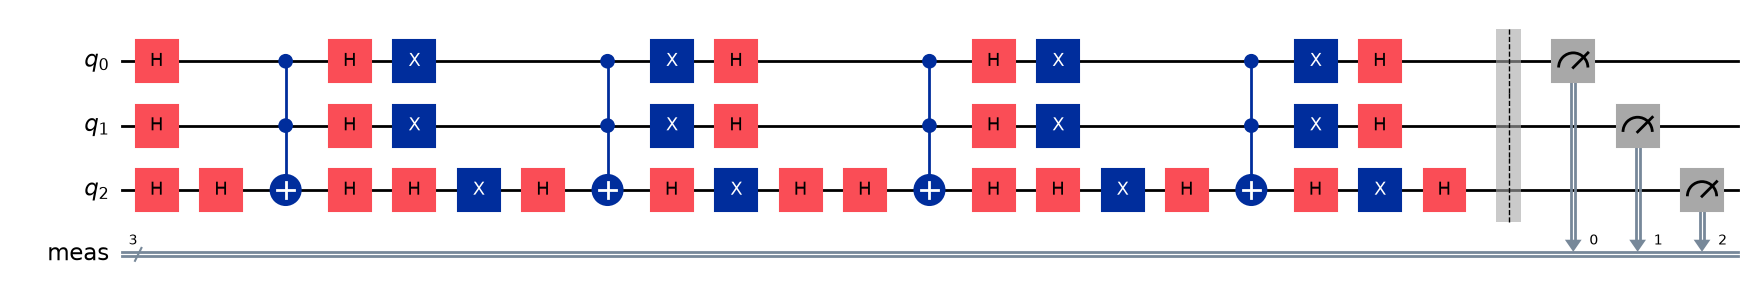

In [3]:
qc_grover = make_grover(3, optimal_iterations(3))
qc_grover.draw('mpl')

箱が4個、8個、16個の場合に、オラクルを使う回数(繰り返しの回数)と、当たりが得られる確率を求めます。確率は、理論値と、回路を1000回実行(1000ショット)して当たりが出た割合の両方を示します。

In [4]:
SHOTS = 1000
sampler = StatevectorSampler(seed=12345)

print("箱の数  古典の平均回数  量子の判定回数  当たりの確率(理論)  当たりの確率(1000ショット)")
for n in (2, 3, 4):
    N = 2**n
    k = optimal_iterations(n)
    counts = sampler.run([make_grover(n, k)], shots=SHOTS).result()[0].data.meas.get_counts()
    measured = counts.get("1" * n, 0) / SHOTS
    print(f"{N:>6} {(N + 1) / 2:>15.1f} {k:>15} {success_probability(n, k):>19.1%} {measured:>27.1%}")

箱の数  古典の平均回数  量子の判定回数  当たりの確率(理論)  当たりの確率(1000ショット)
     4             2.5               1              100.0%                      100.0%
     8             4.5               2               94.5%                       95.5%
    16             8.5               3               96.1%                       97.1%


結果から、次のことが分かります。

- 古典は、箱の数が2倍になると、開ける回数もほぼ2倍になります。
- 量子は、箱の数が4倍(4個→16個)になっても、判定の回数は1回から3回にしか増えていません。
- 量子では、どの場合も、当たりがほぼ確実に得られます。

箱が増えるほど、この差は広がります。これが、探索における量子コンピューターの **利点** です。

> ここで数えた「判定の回数」は、オラクルを使う回数です。回数が少なくて済むことは確かめましたが、1回あたりの操作の重さは、まだ比べていません。それは、後の「制約」の節で確かめます。

## 量子の不思議な性質

先ほどの結果は、第2章で導入した **重ね合わせ** と **干渉** によって得られています。

- **重ね合わせ:** 回路の最初で、すべての箱を等しい確率で含む状態を作ります。この時点で測定すると、どの箱も同じ確率 $1/N$ で得られ、当てずっぽうに選ぶのと変わりません。
- **干渉:** オラクルと拡散操作の組を1回通すたびに、当たりの箱が得られる確率が強め合い、ほかの箱の確率が打ち消し合います。

注意すべき点は、重ね合わせが「$N$ 個の箱をすべて同時に開けた結果を得られる」ことを意味しない点です。測定すると、得られる結果は1つだけです。量子の探索の利点は、干渉によって、**当たりが得られる確率を、繰り返しのたびに高めていく** ことにあります。

箱が16個の場合に、繰り返しの回数ごとの確率を確かめます。

In [5]:
for k in range(optimal_iterations(4) + 1):
    print(f"繰り返し {k} 回: 当たりの確率 {success_probability(4, k):.1%}")

繰り返し 0 回: 当たりの確率 6.2%
繰り返し 1 回: 当たりの確率 47.3%
繰り返し 2 回: 当たりの確率 90.8%
繰り返し 3 回: 当たりの確率 96.1%


繰り返しが0回(重ね合わせを作っただけ)のときは $1/16$(約6%)で、当てずっぽうと同じです。繰り返すたびに確率が高まり、3回で約96%に達します。

> **補足:古典のコンピューターで同じ状態を扱うと**
>
> このノートブックの実験は、古典コンピューター上のシミュレーターで実行しています。シミュレーターは、$n$ 量子ビットの状態を、$2^n$ 個の数(複素数)として記憶します。1つの数に16バイト(複素数を128ビットで保持した場合)を使うと、必要なメモリは次のとおりです。

In [6]:
BYTES_PER_AMPLITUDE = 16  # 複素数を128ビットで保持した場合

UNITS = ["バイト", "KiB", "MiB", "GiB", "TiB"]

for n_qubits in (10, 20, 30, 40):
    size = 2**n_qubits * BYTES_PER_AMPLITUDE
    unit = 0
    while size >= 1024 and unit < len(UNITS) - 1:
        size /= 1024
        unit += 1
    print(f"{n_qubits}量子ビット: {size:g} {UNITS[unit]}")

10量子ビット: 16 KiB
20量子ビット: 16 MiB
30量子ビット: 16 GiB
40量子ビット: 16 TiB


量子ビットが1つ増えるごとに、必要なメモリは2倍になります。30量子ビットで16 GiB、40量子ビットで16 TiB です。量子ビットが増えると、古典のコンピューターで状態をそのまま扱うことは、急速に難しくなります。

## 制約:理論値と実際の結果の差

ここまでで、探索に必要な判定の回数が、$N$ に比例する回数から約 $\sqrt{N}$ 回に減ることを確認しました。この値は、誤りのない理想的な量子コンピューターと、すでに用意された判定の回路を仮定した理論値です。実際に使うときには、次の3つの制約があります。

| 制約 | 内容 |
|---|---|
| 測定 | 1回の実行で得られる結果は1つだけ。途中の状態は見られない |
| ノイズ | 操作のたびに誤りが入り、状態が壊れる |
| データの入力 | 問題のデータを、判定の回路として組み込む手間がかかる |

それぞれを、同じ探索の例で確認します。

### 測定:1回の実行で得られる結果は1つだけ

これまでの実験で「当たりの確率は約96%」と書いてきたのは、回路を1000回実行し、そのうち約96%の回で当たりが得られた、という意味です。回路を1回実行して測定すると、得られる結果は1つだけです。

1回ずつの結果を確かめます。箱が16個の探索を20回実行し、得られた結果を実行した順に並べます。繰り返しの回数は、最適な3回と、それより1回多い4回の2通りで比べます。箱が4個の場合は、当たりの確率が100%なので、結果がばらつく様子を見られません。そのため、箱が16個の場合を使います。

In [7]:
def sample_20_times(iterations):
    """箱が16個の回路を20回実行し、1回ごとの結果を実行した順に返す。"""
    job = StatevectorSampler(seed=12345).run([make_grover(4, iterations)], shots=20)
    return [str(bits) for bits in job.result()[0].data.meas.get_bitstrings()]


for iterations in (optimal_iterations(4), optimal_iterations(4) + 1):
    results = sample_20_times(iterations)
    print(f"繰り返し {iterations} 回: 当たり(1111)が得られた回数 {results.count('1111')} / 20")
    print("  ", " ".join(results[:10]))
    print("  ", " ".join(results[10:]))

繰り返し 3 回: 当たり(1111)が得られた回数 20 / 20
   1111 1111 1111 1111 1111 1111 1111 1111 1111 1111
   1111 1111 1111 1111 1111 1111 1111 1111 1111 1111
繰り返し 4 回: 当たり(1111)が得られた回数 11 / 20
   1000 1011 1111 1111 1110 1011 1111 0110 1111 1111
   1000 1111 1111 0011 1111 1111 1111 1011 1111 0111


結果を読みます。

- **最適な3回では、20回すべてで当たり** が得られました。理論値は約96%なので、まれに外れることもあります。
- **1回多い4回では、20回中11回** しか当たりませんでした。理論値は約58%です。残りの9回は、当たり以外の箱が得られています。

この実験から、測定について次の3点が分かります。

1. **1回の実行で得られるのは、1つの結果だけ** です。その結果が当たりかどうかは、箱を実際に確かめる(検算する)まで分かりません。
2. **途中の状態は見られません。** 測定すると状態が壊れるので、「そろそろ当たりが見えてきた」と途中で確かめて止めることはできません。繰り返しの回数は、事前に計算で決める必要があります。
3. **最適な回数を超えて繰り返すと、悪くなります。** 古典の探索は、続けるほど見つかる確率が上がります。量子の探索は、続けるほど良くなるとは限りません。

3つ目の点を、繰り返しの回数ごとの確率(理論値)で見ます。箱が16個の場合に、繰り返しの回数を0回から12回まで変えて計算し、グラフにします。

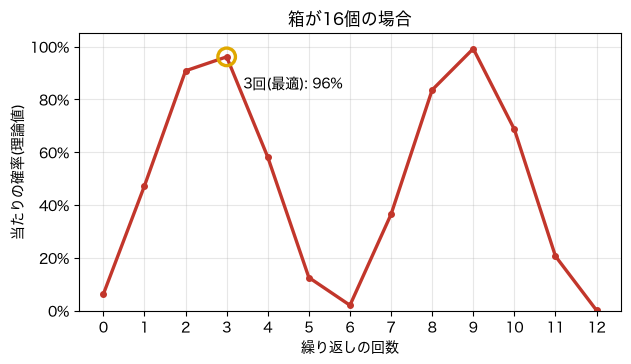

In [8]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter

# 日本語のラベルを表示するため、使える日本語フォントがあれば使う
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
japanese_fonts = [f for f in ("Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic") if f in available_fonts]
plt.rcParams["font.family"] = japanese_fonts + ["sans-serif"]

iterations = list(range(13))
probabilities = [success_probability(4, k) for k in iterations]
best = optimal_iterations(4)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(iterations, probabilities, color="#c2362b", linewidth=2.4, marker="o", markersize=4)
ax.scatter([best], [probabilities[best]], s=160, facecolors="none", edgecolors="#e0a800", linewidths=2.4, zorder=3)
ax.annotate(f"{best}回(最適): {probabilities[best]:.0%}", (best, probabilities[best]), xytext=(12, -14), textcoords="offset points", va="top", ha="left")
ax.set_xlabel("繰り返しの回数")
ax.set_ylabel("当たりの確率(理論値)")
ax.set_title("箱が16個の場合")
ax.set_xticks(iterations)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(alpha=0.3)
plt.show()

箱が16個の場合、当たりの確率は、3回の繰り返しで約96%と最大になります。4回に増やすと約58%、6回では約2%まで下がり、9回で約99%に戻ります。確率は、繰り返しの回数に対して周期的に増減します。量子の探索では、**最適な回数を事前に計算して、そこで止める** 必要があります。

### ノイズ:操作のたびに誤りが入る

ここまでのシミュレーションは、誤りのない理想的な量子コンピューターを仮定していました。実際の量子コンピューターでは、ゲートを実行するたびに、わずかな誤りが入ります。特に、2つの量子ビットにまたがるゲート(CX ゲート)は、1つの量子ビットだけに作用するゲートより、誤りが大きいのが一般的です。

箱の数を増やしながら、ノイズありのシミュレーターで当たりの確率を測ります。誤りの大きさは、この教材で置いた仮定値で、実機の測定値ではありません。

| ゲート | 誤りの確率(仮定値) |
|---|---|
| 1量子ビットゲート | 0.1% |
| 2量子ビットゲート (CX) | 1% |

回路は、これらのゲートだけを使う形に分解してから実行します。比較のため、誤りのない場合の確率(理論値)も並べます。

In [9]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

# この教材で置いた仮定値(実機の測定値ではない)
ERROR_1Q = 0.001
ERROR_2Q = 0.01

noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(depolarizing_error(ERROR_1Q, 1), ["sx", "x"])
noise_model.add_all_qubit_quantum_error(depolarizing_error(ERROR_2Q, 2), ["cx"])
noisy_backend = AerSimulator(noise_model=noise_model)
BASIS_GATES = ["cx", "rz", "sx", "x"]
NOISY_SHOTS = 2000

print("箱の数  CXの数  誤りのない場合  ノイズあり")
for n in (2, 3, 4, 5, 6):
    k = optimal_iterations(n)
    decomposed = transpile(make_grover(n, k), basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=12345)
    counts = noisy_backend.run(decomposed, shots=NOISY_SHOTS, seed_simulator=12345).result().get_counts()
    noisy = counts.get("1" * n, 0) / NOISY_SHOTS
    print(f"{2**n:>6} {decomposed.count_ops().get('cx', 0):>7} {success_probability(n, k):>14.1%} {noisy:>10.1%}")

箱の数  CXの数  誤りのない場合  ノイズあり
     4       2         100.0%      98.2%
     8      24          94.5%      76.9%
    16      84          96.1%      47.6%
    32     288          99.9%      11.1%
    64    1008          99.7%       1.6%


結果を読みます。

- **誤りのない場合は、どの箱の数でも94%以上** です。一方、ノイズがあると、箱が16個で約48%、32個で約11%に下がります。下がった分は、ノイズによるものです。
- **箱が64個では、約1.6%** です。64個からでたらめに1つ選んだときの確率($1/64 \approx 1.6\%$)とほぼ同じで、量子の探索が、当てずっぽうと変わらなくなっています。
- **下がり方は、CX ゲートの数と対応しています。** 箱が増えるほど、繰り返しの回数と、1回の繰り返しに含まれるゲートの数がともに増え、CX の数は2個から1008個まで増えます。誤りは、ゲートが増えるたびに積み重なります。

理論上は約 $\sqrt{N}$ 回で済むという利点は、ノイズがあると、回路が大きくなるにつれて打ち消されていきます。

> ここでのノイズの大きさは、この教材で置いた仮定値です。実機の誤りの大きさは、機種や時期によって異なります。ノイズの原因と、それを抑える方法は、今後公開予定の章で扱います。

### データの入力:問題を回路に組み込むコスト

ここまでの探索では、当たりを $|11\cdots1\rangle$ に決め、それを判定するオラクルを最初から用意していました。実際の問題では、何が当たりかは、問題のデータで決まります。問題のデータを、オラクルとして回路に組み込む手間が、3つ目の制約です。

#### オラクルの大きさ

まず、当たりを $|11\cdots1\rangle$ に決めた、最も単純なオラクルの大きさを数えます。オラクルを、ノイズの実験と同じゲートに分解し、CX ゲートの数を数えます。

In [10]:
print("箱の数  オラクル1回あたりの CX の数")
for n in (2, 3, 4, 5, 6):
    oracle = transpile(make_oracle(n), basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=12345)
    print(f"{2**n:>6} {oracle.count_ops().get('cx', 0):>24}")

箱の数  オラクル1回あたりの CX の数
     4                        1
     8                        6
    16                       14
    32                       36
    64                       84


最も単純なオラクルでも、箱が増えると、1回あたりの CX の数は増えます。判定の回数が約 $\sqrt{N}$ 回に減っても、1回あたりの回路が大きくなるので、実行する操作の量は、回数の減り方ほどには減りません。

#### データの表からオラクルを作る

次に、当たりがデータの表で決まる場合を考えます。$N$ 行の表があり、ある値に等しい行を探す問題です。この場合、オラクルを作るには、表の各行が条件に合うかを確かめ、合う行の箱を判定する回路を書き込む必要があります。

次のコードは、表を1行ずつ確かめて、オラクルを作ります。確かめた行の数と、条件に合った行(当たりの箱)も記録します。

In [11]:
from qiskit.quantum_info import Operator


def oracle_from_table(table, target):
    """表を1行ずつ確かめ、値が target に等しい行の箱を判定するオラクルを作る。"""
    n = int(math.log2(len(table)))
    circuit = QuantumCircuit(n)
    rows_checked = 0
    matched = []
    for box, value in enumerate(table):
        rows_checked += 1  # 表の行を1つ確かめる
        if value == target:
            matched.append(box)
            zeros = [i for i in range(n) if not (box >> i) & 1]
            if zeros:
                circuit.x(zeros)
            circuit.compose(make_oracle(n), inplace=True)
            if zeros:
                circuit.x(zeros)
    return circuit, rows_checked, matched


rng = random.Random(12345)
print("箱の数  確かめた行の数  オラクルを作り終えた時点で分かっている当たり  古典の平均回数  量子の判定回数")
for n in (2, 3, 4, 8, 10):
    N = 2**n
    table = list(range(N))
    rng.shuffle(table)
    circuit, rows_checked, matched = oracle_from_table(table, target=N // 3)
    if n <= 4:  # 小さい場合は、作ったオラクルが当たりの箱だけを判定していることを確かめる
        flipped = [i for i, v in enumerate(Operator(circuit).data.diagonal()) if v.real < 0]
        assert flipped == matched == [table.index(N // 3)]
    print(f"{N:>6} {rows_checked:>15} {str(matched):>44} {(N + 1) / 2:>15.1f} {optimal_iterations(n):>15}")

箱の数  確かめた行の数  オラクルを作り終えた時点で分かっている当たり  古典の平均回数  量子の判定回数
     4               4                                          [0]             2.5               1
     8               8                                          [5]             4.5               2
    16              16                                         [15]             8.5               3
   256             256                                        [153]           128.5              12
  1024            1024                                        [348]           512.5              25


結果を読みます。

- **この作り方では、表の全行を確かめています。** 確かめた行の数は、箱の数 $N$ と同じです。古典の探索は、平均 $(N+1)/2$ 回で済みます。
- **オラクルを作り終えた時点で、当たりの箱はもう分かっています。** オラクルを作る作業そのものが、古典の探索になっているためです。この後に量子の探索を約 $\sqrt{N}$ 回行っても、得になりません。

Grover の探索が約 $\sqrt{N}$ 回で済むのは、オラクルが、表を読まずに回路として書ける場合です。量子の高速化をうたう手法の多くは、古典のデータを量子コンピューターに速く読み込めることを前提にしています。

この違いが、Grover の探索が向く問題と向かない問題を分けます。

| 問題の種類 | オラクルの作り方 | 高速化の利点 |
|---|---|---|
| 条件を関数として書ける(たとえば、論理式を満たす入力を探す) | 条件を、そのまま回路として書ける | 保たれうる |
| 古典のデータの表から探す | 表を読み込んで、回路に組み込む必要がある | 打ち消されうる |

## 利点と制約から、適用の判断へ

探索問題を例に、量子コンピューターの利点と制約を確認しました。

| | 確認したこと |
|---|---|
| 利点 | 探索に必要な判定の回数が、$N$ に比例する回数から約 $\sqrt{N}$ 回に減る。背景には、重ね合わせと干渉がある |
| 制約:測定 | 1回の実行で得られる結果は1つ。繰り返しの回数を事前に決める必要があり、超えると確率が下がる |
| 制約:ノイズ | 回路が大きくなるほど、当たりの確率が下がる。この教材の仮定値では、箱が64個で当てずっぽうと同じ水準になった |
| 制約:データの入力 | 表のデータからオラクルを作ると、全行を確かめる必要があり、その時点で答えが分かってしまう |

「約 $\sqrt{N}$ 回」という高速化と、それを得るためのコストを比べることが、量子コンピューターの適用を考えるときの基本になります。扱う問題で量子計算が優位になるかは、次の問いで判断できます。

1. **減るのは、何の回数か。** 判定の回数が減っても、判定の回路を作る手間や、1回あたりの回路の大きさが増えれば、全体では得になりません。
2. **問題のデータは、回路として小さく書けるか。** 条件が式や関数で書けるのか、大量の表を読み込む必要があるのかで、オラクルの大きさが大きく変わります。
3. **必要な回路の大きさは、今のノイズに耐えられるか。** 理論上の回数が少なくても、回路が大きければ、ノイズで結果が壊れます。
4. **結果を、自分で検算できるか。** 1回の実行で得られるのは1つの結果で、それが正しいかは、別に確かめる必要があります。

## 実行環境

このノートブックの実行に使ったライブラリのバージョンです。

In [12]:
import ast
import platform
from importlib.metadata import packages_distributions, version

# このノートブックが import している Qiskit 系のパッケージだけを表示する
used = set()
for source in In:
    try:
        nodes = ast.walk(ast.parse(source))
    except SyntaxError:  # ! や % で始まるセルは読み飛ばす
        continue
    for node in nodes:
        if isinstance(node, ast.Import):
            tops = [a.name.split(".")[0] for a in node.names]
        elif isinstance(node, ast.ImportFrom) and node.level == 0:
            tops = [node.module.split(".")[0]]
        else:
            continue
        for top in tops:
            if top.startswith("qiskit"):
                used.update(packages_distributions().get(top, []))

print(f"{'python':<24} {'.'.join(platform.python_version().split('.')[:2])}")
for name in sorted(used):
    print(f"{name:<24} {version(name)}")

python                   3.12
qiskit                   2.4.2
qiskit-aer               0.18.0
